#### Загрузка датасета и предобработка

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from catboost import CatBoostRegressor
import pmdarima as pm
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

# Загрузка данных
df = pd.read_csv('ETTh1.csv')

print(f"Размер датасета: {df.shape}")
df.head()

Размер датасета: (17420, 8)


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


Преобразованние строковых данных даты в формат datetime и устанвка их в качестве индекса

In [3]:
df['Datetime'] = pd.to_datetime(df['date'])
df = df.set_index('Datetime').sort_index()
print(f"Колонки: {df.columns.tolist()}")

Колонки: ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']


Проверка дубликатов и целостности

In [4]:
duplicates = df.index.duplicated().sum()
print(f"Найдено дубликатов в датах: {duplicates}")

if duplicates > 0:
    df = df[~df.index.duplicated(keep='first')]
    print("Дубликаты удалены (оставлены первые вхождения).")

full_time = pd.date_range(start=df.index.min(), end=df.index.max(), freq='h')

missing_hours = full_time.difference(df.index)
print(f"Найдено пропущенных значений в датасете: {len(missing_hours)}")

if len(missing_hours) > 0:
    df = df.reindex(full_time).interpolate(method='linear')
    df.index.name = 'Datetime'
    print(f"Итоговый размер данных: {df.shape[0]} строк.")

Найдено дубликатов в датах: 0
Найдено пропущенных значений в датасете: 0


#### Визуальный анализ в различных временных масштабах

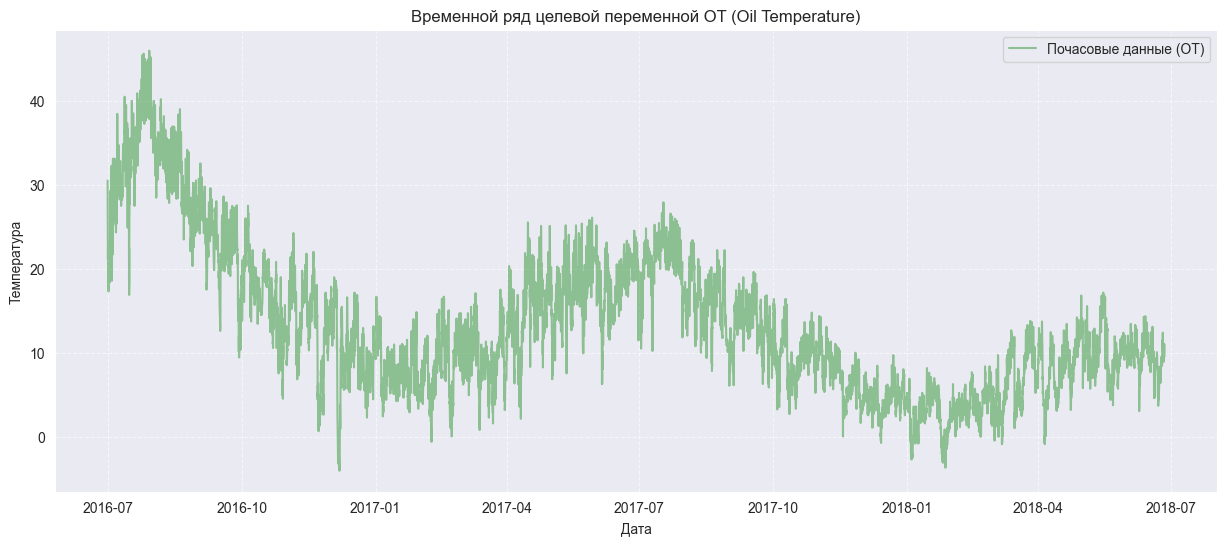

In [5]:
plt.figure(figsize=(15, 6))

# Отрисовка исходных данных
plt.plot(df.index, df['OT'],color='green', label='Почасовые данные (OT)', alpha=0.4)

plt.title('Временной ряд целевой переменной OT (Oil Temperature)')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

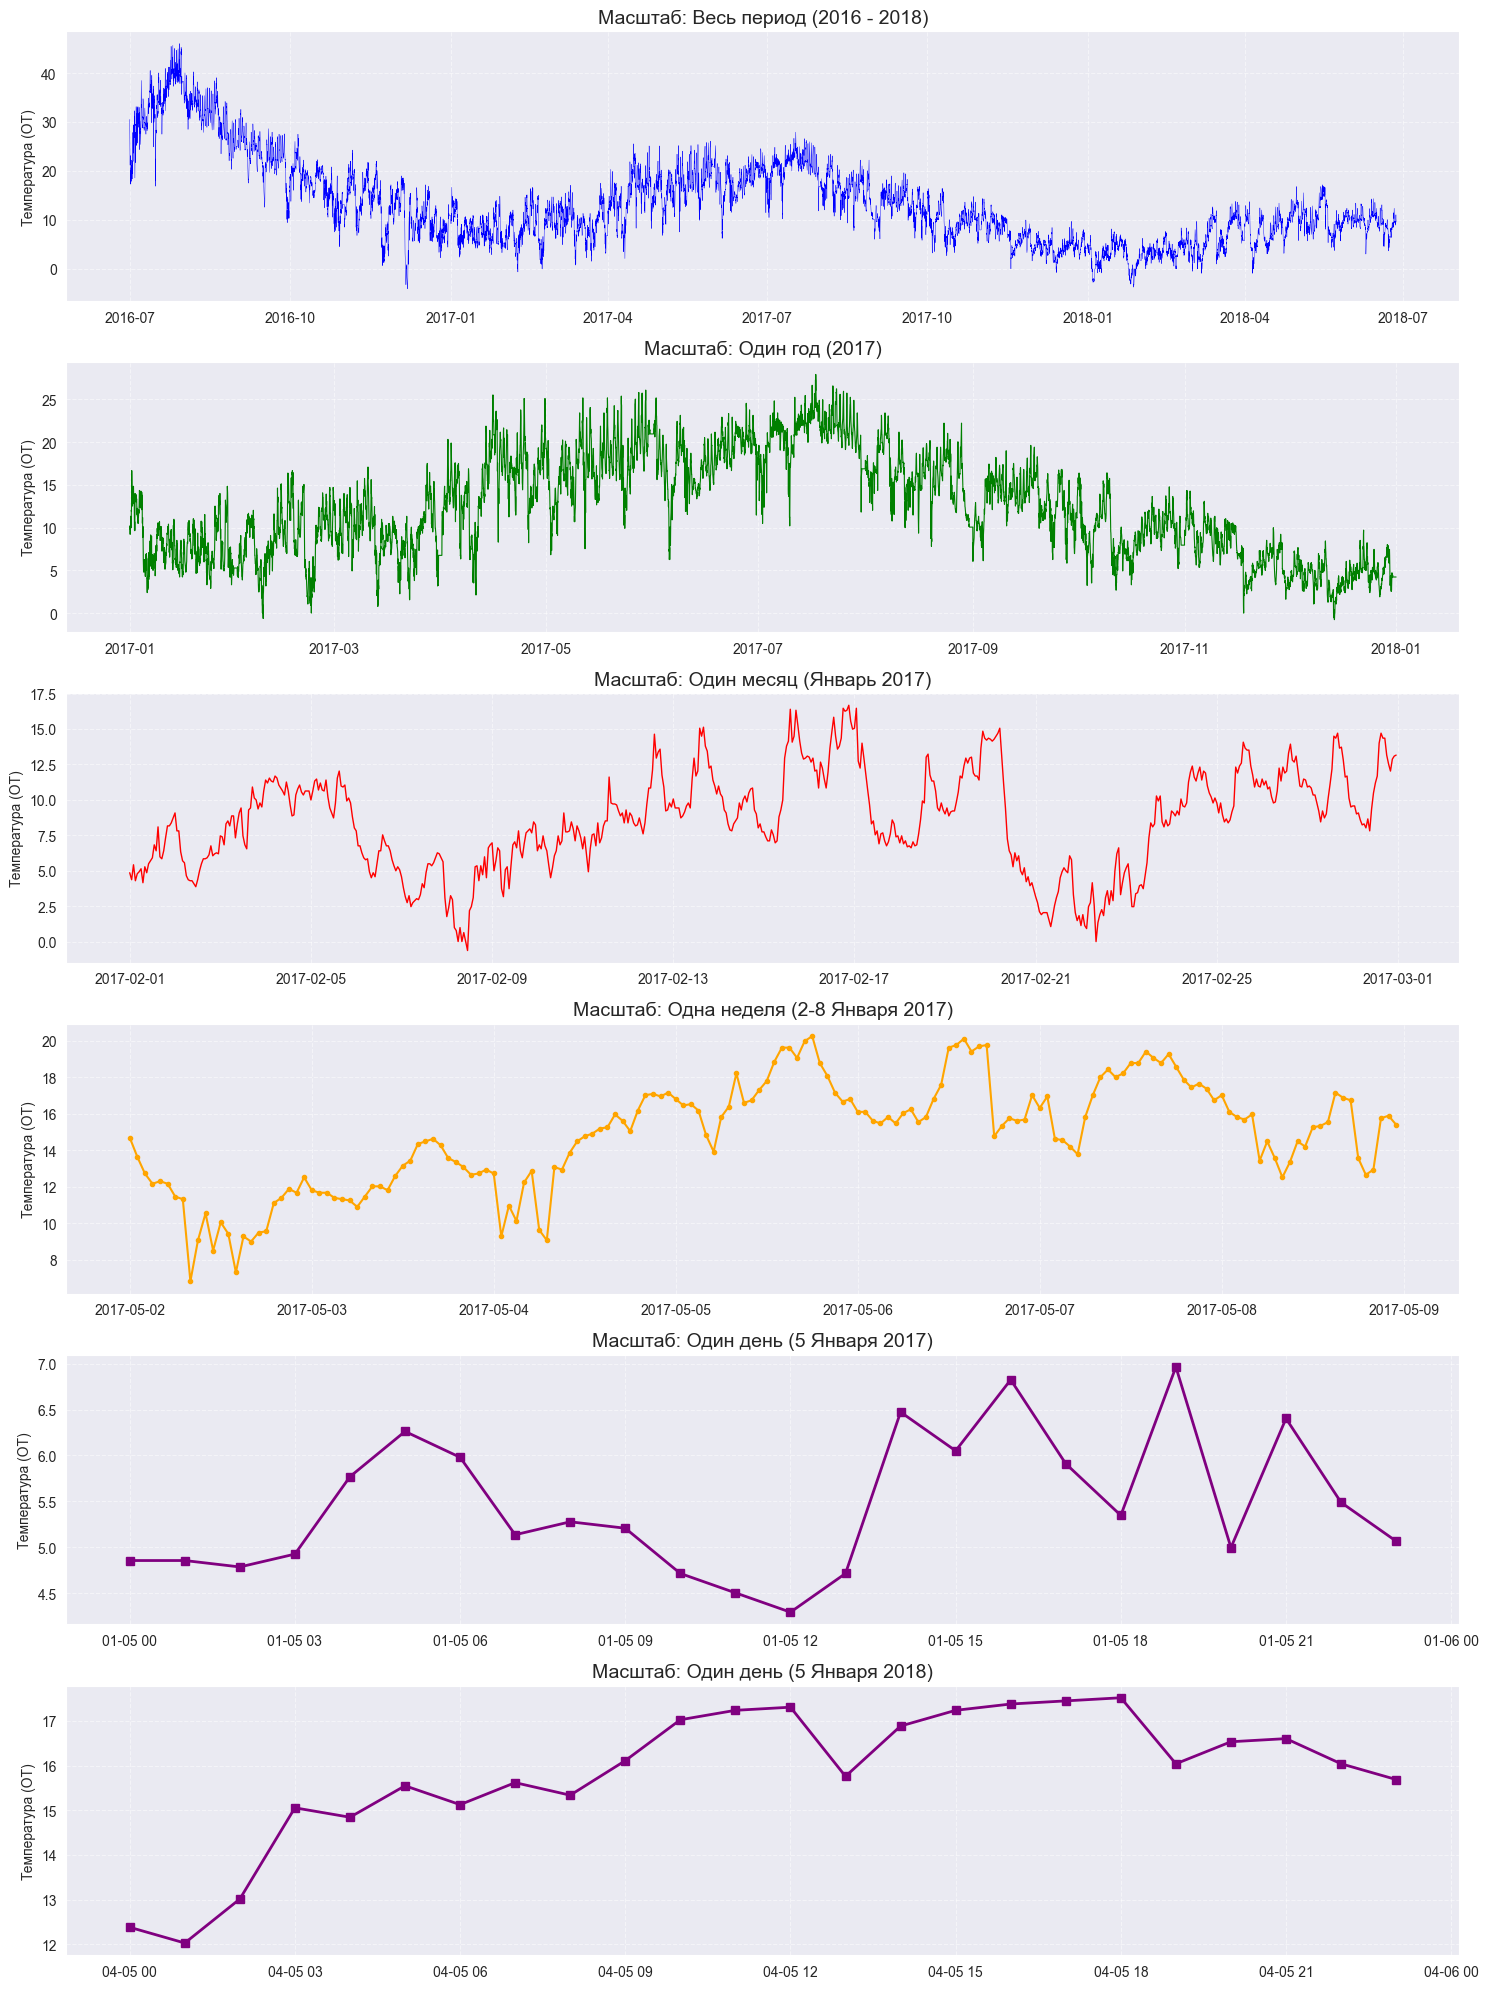

In [6]:
# Настройка визуализации для различных масштабов
fig, axes = plt.subplots(6, 1, figsize=(15, 20))

# 1. Весь период наблюдения (общий тренд)
axes[0].plot(df.index, df['OT'], color='blue', linewidth=0.3)
axes[0].set_title('Масштаб: Весь период (2016 - 2018)', fontsize=14)

# 2. Годовой цикл (сезонные изменения)
# Выбираем 2017 год
df_year = df.loc['2017']
axes[1].plot(df_year.index, df_year['OT'], color='green', linewidth=0.8)
axes[1].set_title('Масштаб: Один год (2017)', fontsize=14)

# 3. Месячный цикл
df_month = df.loc['2017-02']
axes[2].plot(df_month.index, df_month['OT'], color='red', linewidth=1)
axes[2].set_title('Масштаб: Один месяц (Январь 2017)', fontsize=14)

# 4. Недельный цикл
df_week = df.loc['2017-05-02':'2017-05-08']
axes[3].plot(df_week.index, df_week['OT'], color='orange', linewidth=1.5, marker='o', markersize=3)
axes[3].set_title('Масштаб: Одна неделя (2-8 Января 2017)', fontsize=14)

# 5. Суточный цикл
df_day = df.loc['2017-01-05']
axes[4].plot(df_day.index, df_day['OT'], color='purple', linewidth=2, marker='s')
axes[4].set_title('Масштаб: Один день (5 Января 2017)', fontsize=14)

df_day = df.loc['2017-04-05']
axes[5].plot(df_day.index, df_day['OT'], color='purple', linewidth=2, marker='s')
axes[5].set_title('Масштаб: Один день (5 Января 2018)', fontsize=14)

for ax in axes:
    ax.set_ylabel('Температура (OT)')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

На первом графике четко видны присутсвие тренда на спад температуры и сезонность связанная с теплыми и холодными временнами года

#### Проверка на стационарность (Тест Дики-Фуллера)

In [7]:
def check_stationarity(series):
    result = adfuller(series.values)
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4e}')
    if result[1] <= 0.05:
        print("Вывод: Ряд стационарен (нулевая гипотеза отвергнута).")
    else:
        print("Вывод: Ряд нестационарен (нулевая гипотеза не отвергнута).")

check_stationarity(df['OT'])

ADF Statistic: -3.4880
p-value: 8.3016e-03
Вывод: Ряд стационарен (нулевая гипотеза отвергнута).


#### Декомпозиция ряда


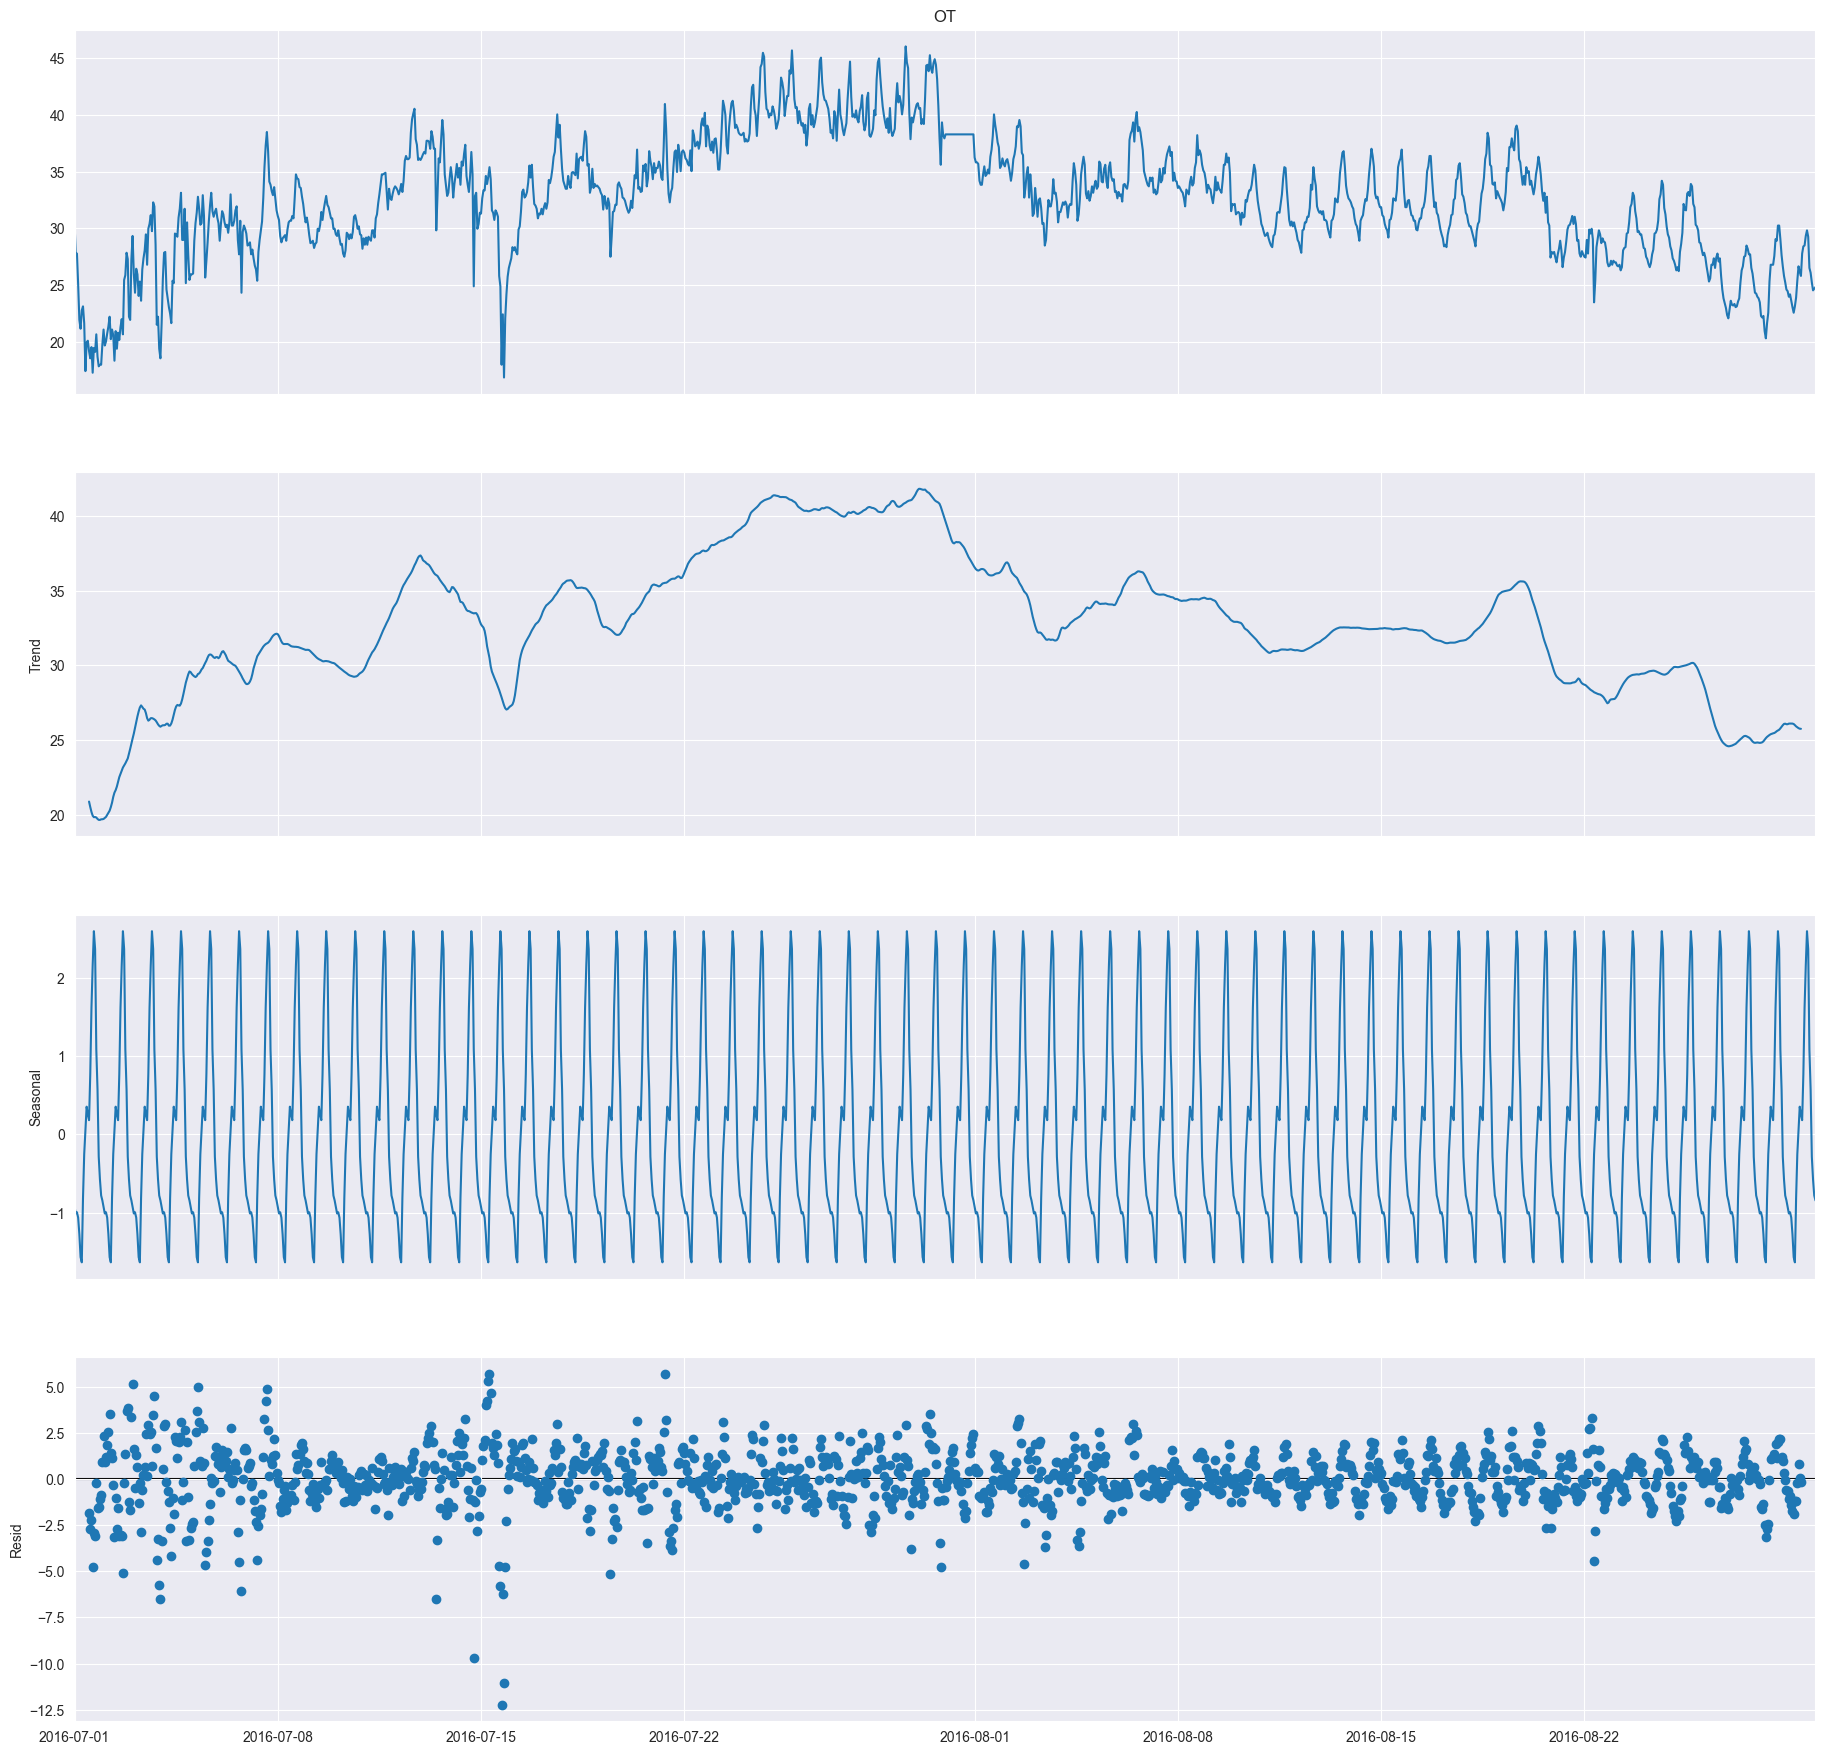

In [8]:
result = seasonal_decompose(df['OT'][:24*30*2], model='additive', period=24)

fig = result.plot()
fig.set_size_inches(20, 20)
plt.show()

#### Классический ML

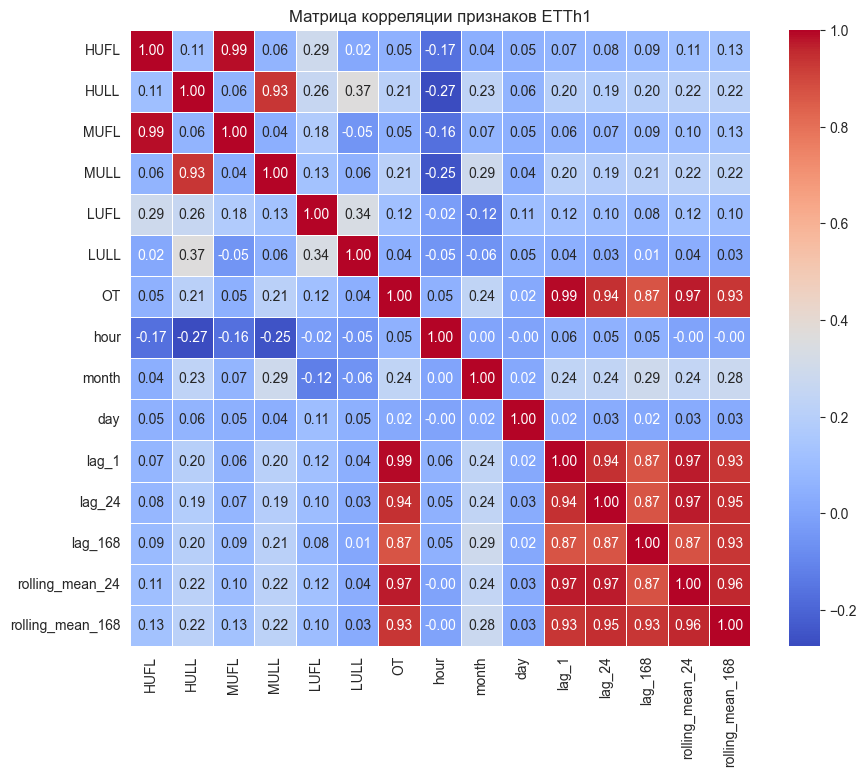

In [9]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_error, mean_squared_error

df_ml = df.copy()

# 1. Подготовка календарных признаков
df_ml['hour'] = df_ml.index.hour
df_ml['month'] = df_ml.index.month
df_ml['day'] = df_ml.index.day

# 2. Выделение лагов (что происходило 1 час назад, сутки назад и неделю назад)
df_ml['lag_1'] = df_ml['OT'].shift(1)
df_ml['lag_24'] = df_ml['OT'].shift(24)
df_ml['lag_168'] = df_ml['OT'].shift(168)

# 3. Скользящие средние (средняя температура за прошедшие сутки и прошедшую неделю)
df_ml['rolling_mean_24'] = df_ml['OT'].shift(1).rolling(window=24).mean()
df_ml['rolling_mean_168'] = df_ml['OT'].shift(1).rolling(window=168).mean()

# Удаляем пустые строки, образовавшиеся из-за сдвига на 168 часов (неделю)
df_ml.dropna(inplace=True)

corr_matrix = df_ml.drop(columns=['date'], errors='ignore').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)

plt.title('Матрица корреляции признаков ETTh1')
plt.show()



In [10]:
# 4. Выделение 90 дней на тест (90 дней * 24 часа = 2160 часов)
test_hours = 90 * 24
train = df_ml.iloc[:-test_hours]
test = df_ml.iloc[-test_hours:]

# Удаляем целевую переменную и мультиколлинеарные признаки
cols_to_drop = ['OT','date','MUFL','MULL']

X_train = train.drop(cols_to_drop, axis=1)
y_train = train['OT']
X_test = test.drop(cols_to_drop, axis=1)
y_test = test['OT']

# 5. Обучение моделей
rf_model = RandomForestRegressor(n_estimators=200, random_state=1337)
xgb_model = xgb.XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=5, random_state=1337)
cb_model = CatBoostRegressor(iterations=200, learning_rate=0.05, depth=5, random_state=1337, verbose=0)

rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)
cb_model.fit(X_train, y_train)

pred_rf = rf_model.predict(X_test)
pred_xgb = xgb_model.predict(X_test)
pred_cb = cb_model.predict(X_test)




In [11]:
# Расчет метрик
def get_smape(y_true, y_pred):
    return 100/len(y_true) * np.sum(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-6))

def get_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    smape_val = get_smape(y_true, y_pred)
    return mae, rmse, smape_val

metrics_rf = get_metrics(y_test, pred_rf)
metrics_xgb = get_metrics(y_test, pred_xgb)
metrics_cb = get_metrics(y_test, pred_cb)

results_ml = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost', 'CatBoost'],
    'MAE': [metrics_rf[0], metrics_xgb[0], metrics_cb[0]],
    'RMSE': [metrics_rf[1], metrics_xgb[1], metrics_cb[1]],
    'MAPE (%)': [metrics_rf[2], metrics_xgb[2], metrics_cb[2]]
})

display(results_ml.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Random Forest,0.46,0.66,6.61
1,XGBoost,0.42,0.63,6.19
2,CatBoost,0.44,0.64,6.27


#### Визуализация прогнозов

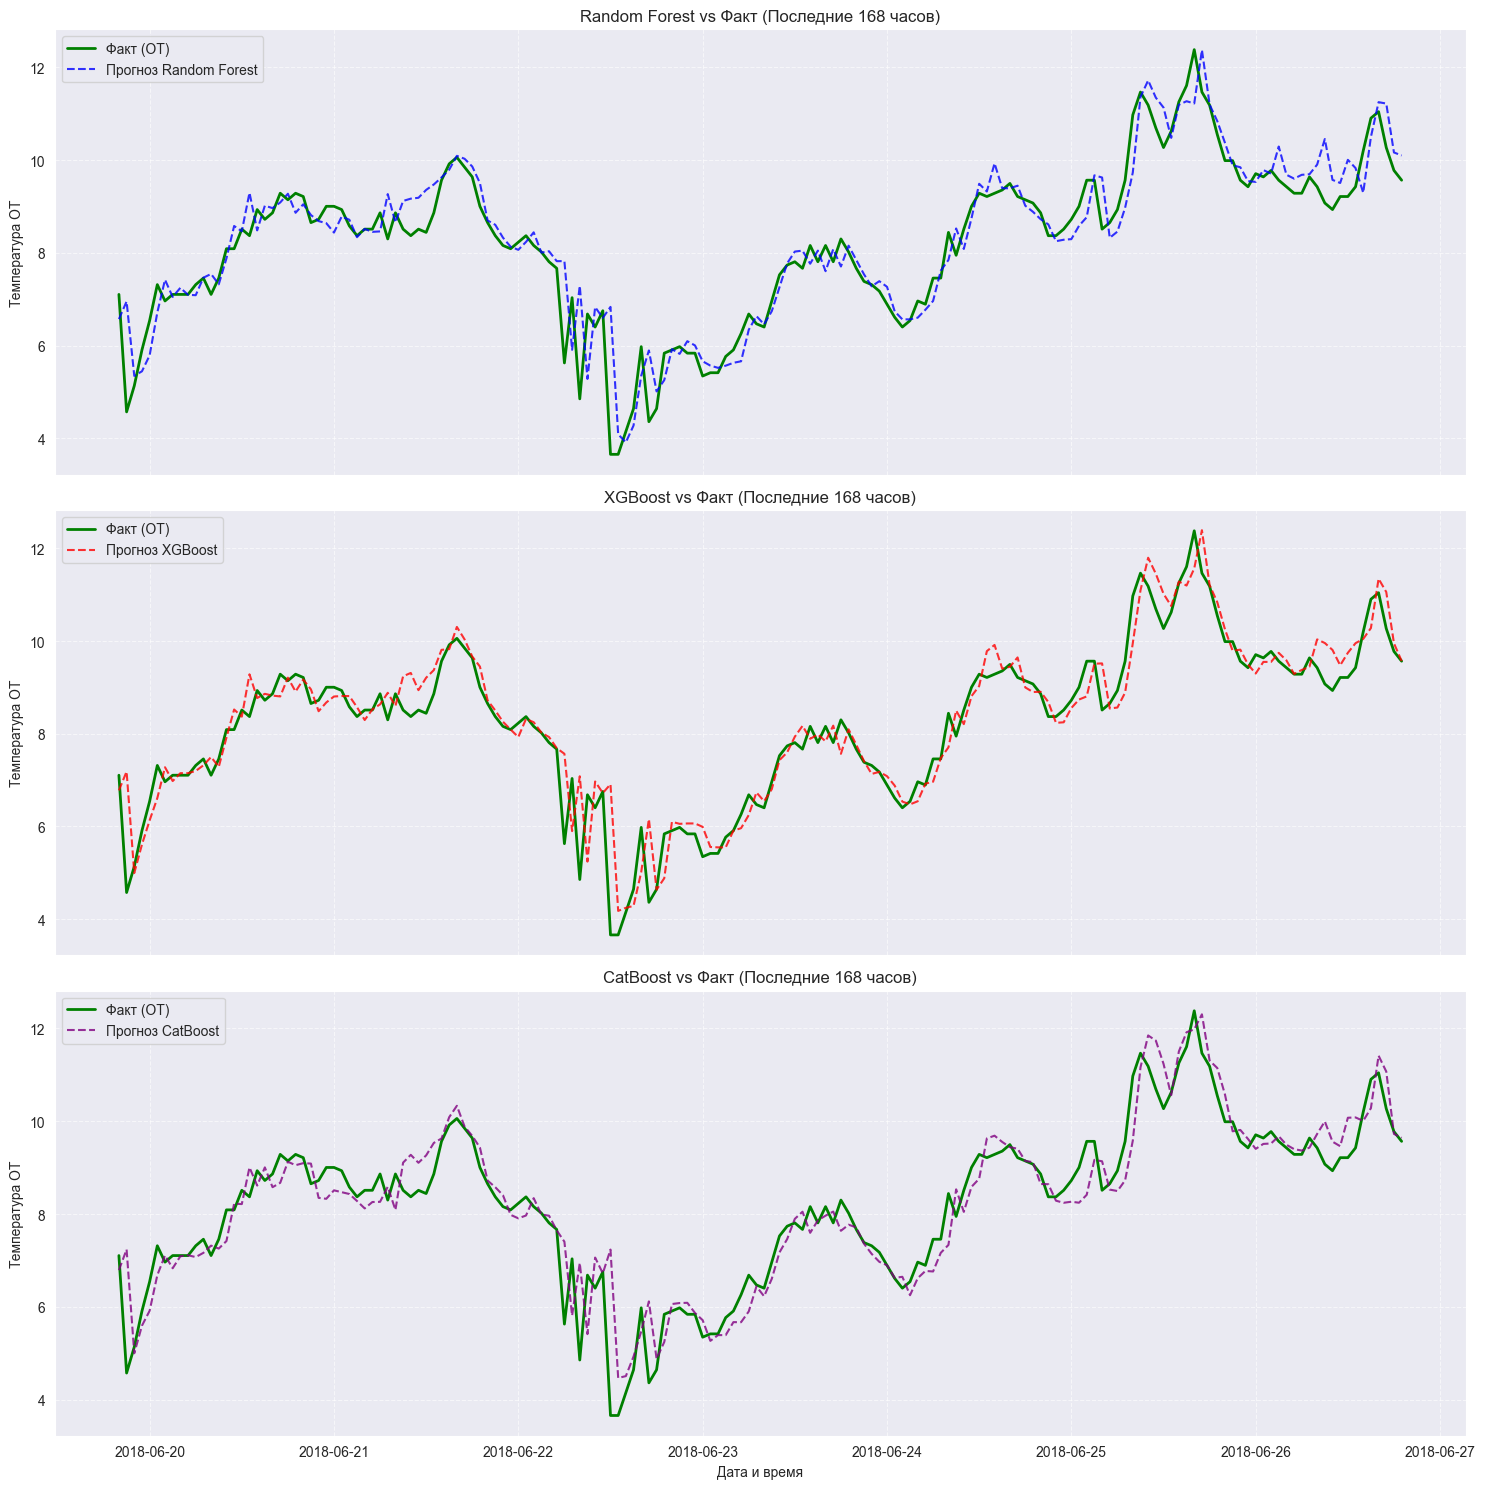

In [22]:
# Настройка: сколько последних часов визуализировать, чтобы увидеть детали (например, последняя неделя)
zoom_hours = 168

fig, axes = plt.subplots(3, 1, figsize=(15, 15), sharex=True)

# 1. Random Forest
axes[0].plot(y_test.index[-zoom_hours:], y_test.values[-zoom_hours:], label='Факт (OT)', color='green', linewidth=2)
axes[0].plot(y_test.index[-zoom_hours:], pred_rf[-zoom_hours:], label='Прогноз Random Forest', color='blue', alpha=0.8,
             linestyle='--')
axes[0].set_title(f'Random Forest vs Факт (Последние {zoom_hours} часов)')
axes[0].set_ylabel('Температура OT')
axes[0].legend(loc='upper left')
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. XGBoost
axes[1].plot(y_test.index[-zoom_hours:], y_test.values[-zoom_hours:], label='Факт (OT)', color='green', linewidth=2)
axes[1].plot(y_test.index[-zoom_hours:], pred_xgb[-zoom_hours:], label='Прогноз XGBoost', color='red', alpha=0.8,
             linestyle='--')
axes[1].set_title(f'XGBoost vs Факт (Последние {zoom_hours} часов)')
axes[1].set_ylabel('Температура OT')
axes[1].legend(loc='upper left')
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. CatBoost
axes[2].plot(y_test.index[-zoom_hours:], y_test.values[-zoom_hours:], label='Факт (OT)', color='green', linewidth=2)
axes[2].plot(y_test.index[-zoom_hours:], pred_cb[-zoom_hours:], label='Прогноз CatBoost', color='purple', alpha=0.8,
             linestyle='--')
axes[2].set_title(f'CatBoost vs Факт (Последние {zoom_hours} часов)')
axes[2].set_ylabel('Температура OT')
axes[2].set_xlabel('Дата и время')
axes[2].legend(loc='upper left')
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#### Статистические методы

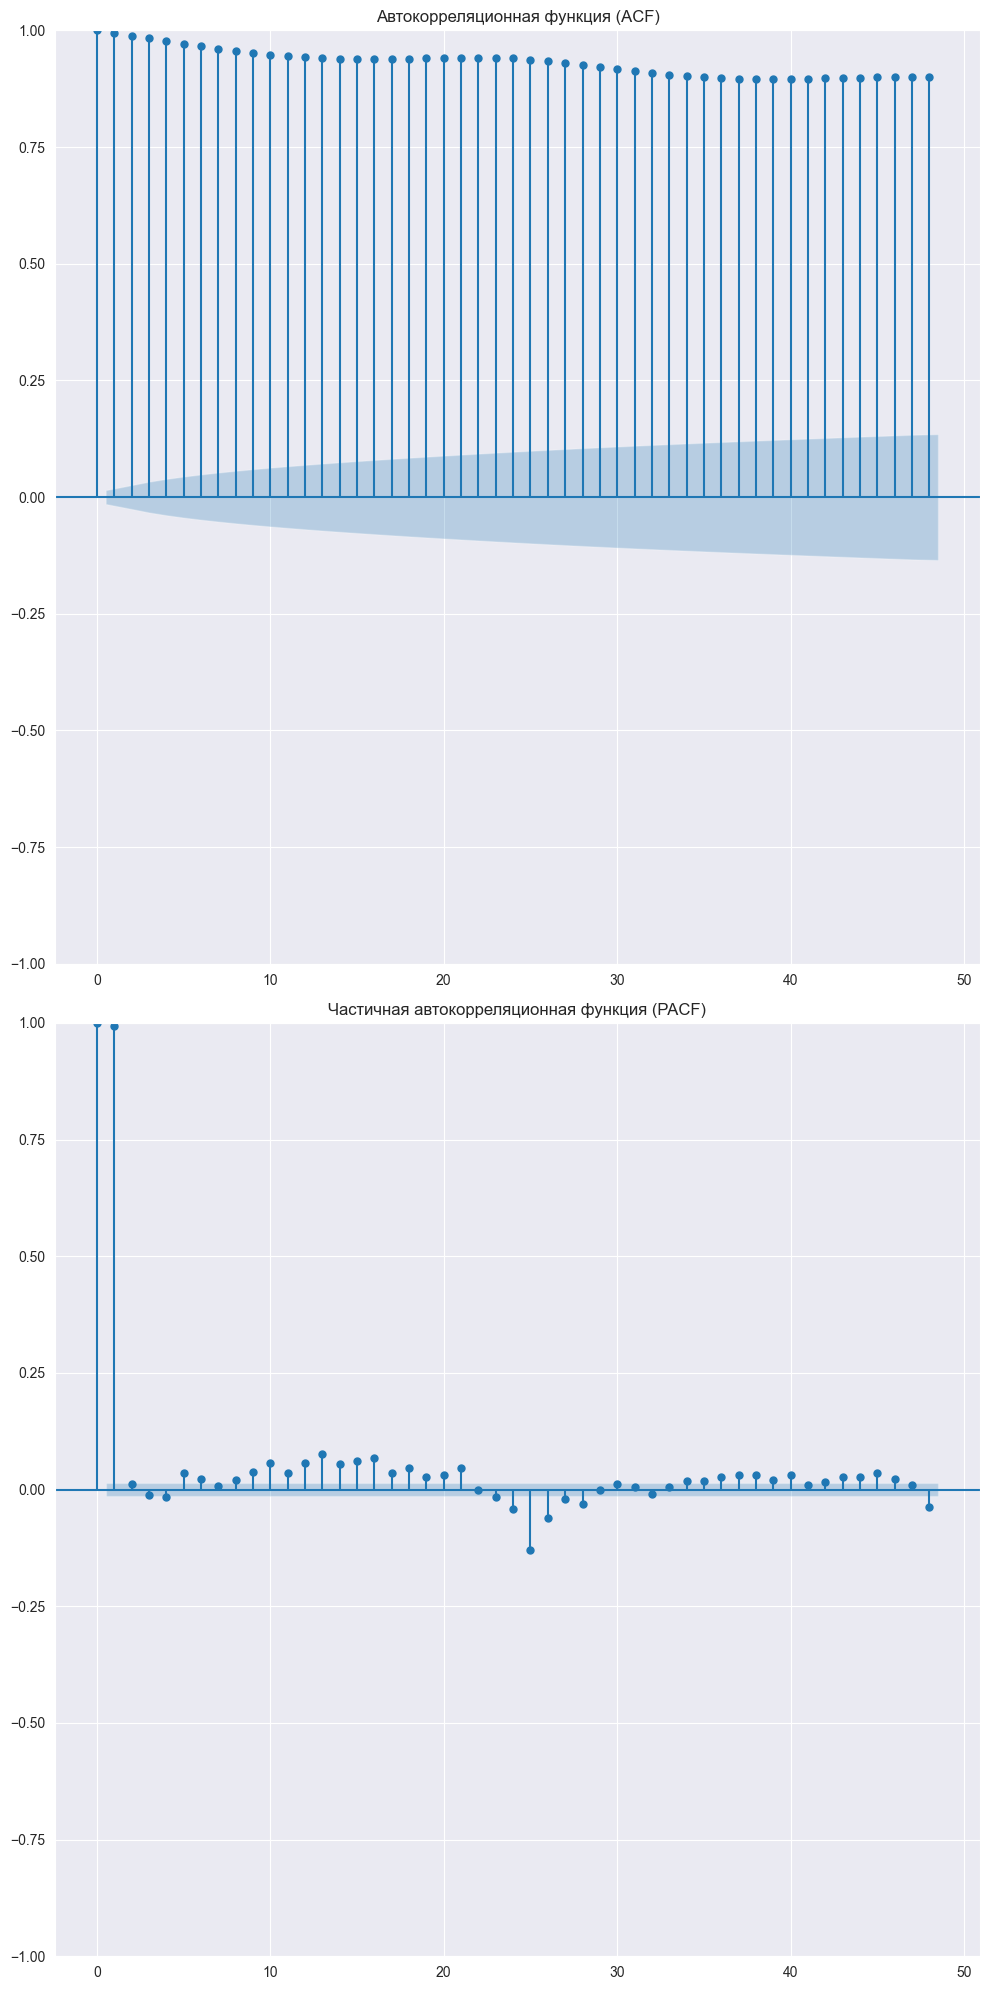

In [13]:
# Построение коррелограмм для определения лагов
fig, ax = plt.subplots(2, 1, figsize=(10, 20))

# Анализ на глубину 5 суток (120 часов) для выявления сезонных всплесков
plot_acf(df['OT'], lags=48, ax=ax[0])
plot_pacf(df['OT'], lags=48, ax=ax[1])

ax[0].set_title('Автокорреляционная функция (ACF)')
ax[1].set_title('Частичная автокорреляционная функция (PACF)')
plt.tight_layout()

plt.show()

Для ARIMA (p,d,q):

  * d=1: Так как ACF затухает медленно, нам нужно взять первую разность , чтобы убрать тренд и сделать ряд стационарным.

  *  p=1 или 2: На PACF мы видим резкий обрыв после первых лагов. Это указывает на порядок авторегрессии AR(1) или AR(2).

  *  q=0 или 1: Поскольку PACF обрывается, а ACF затухает плавно, процесс скорее авторегрессионный (AR), чем скользящего среднего (MA). Начните с 0.

     ARIMA: (1,1,0) или (2,1,0).

Для SARIMA (p,d,q)×(P,D,Q)s:

Здесь мы добавляем сезонную часть. Поскольку у нас почасовые данные, сезонный период s=24.

   * D=1

   * P=1: На PACF в районе 24-го лага есть всплеск — это сезонное авторегрессионное влияние.

   * Q=0 или 1: Аналогично обычным параметрам.

#### ARIMA


In [14]:
model_arima = ARIMA(y_train, order=(2, 1, 0))
results_arima = model_arima.fit()

# 2. Прогноз на длину тестовой выборки
forecast_arima = results_arima.get_forecast(steps=len(y_test))
y_pred_arima = forecast_arima.predicted_mean

# 3. Расчет метрик без использования y_safe
# Чтобы MAPE не выдал ошибку на нулях, используем маску (только значения > 0)
mask = y_test > 0
mape_arima = np.mean(np.abs((y_test[mask] - y_pred_arima[mask]) / y_test[mask])) * 100

mae_arima = mean_absolute_error(y_test, y_pred_arima)

print(f"--- Результаты ARIMA (2, 1, 0) ---")
print(f"MAE: {mae_arima:.2f}")
print(f"MAPE (только для значений > 0): {mape_arima:.2f}%")


C:\Users\Denis\PycharmProjects\JupyterProject\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\Denis\PycharmProjects\JupyterProject\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\Denis\PycharmProjects\JupyterProject\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


--- Результаты ARIMA (2, 1, 0) ---
MAE: 2.72
MAPE (только для значений > 0): 46.25%


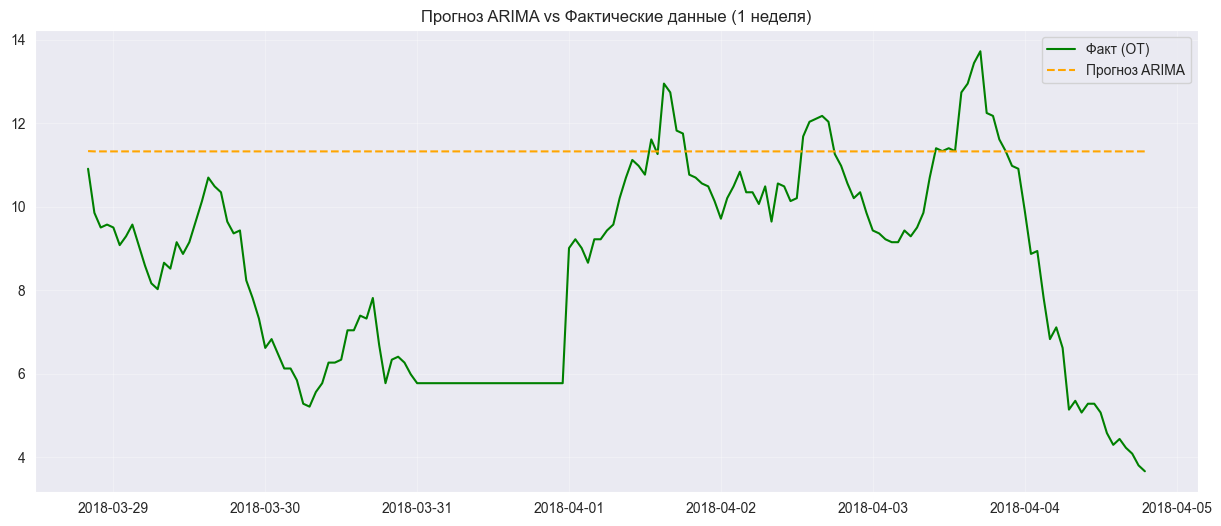

In [15]:
# 4. Визуализация (первые 168 часов теста для наглядности)
plt.figure(figsize=(15, 6))
plt.plot(y_test.index[:168], y_test.values[:168], label='Факт (OT)', color='green')
plt.plot(y_test.index[:168], y_pred_arima[:168], label='Прогноз ARIMA', color='orange', linestyle='--')
plt.title('Прогноз ARIMA vs Фактические данные (1 неделя)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### SARIMA

In [16]:
test_sarima = y_test.iloc[-48:]

train_sarima = y_train.iloc[-800:]

# Используем p=2, d=1, q=0 и сезонные P=1, D=1, Q=0
model_sarima = SARIMAX(train_sarima,
                       order=(2, 1, 0),
                       seasonal_order=(1, 1, 0, 24),
                       enforce_stationarity=False,
                       enforce_invertibility=False)

results_sarima = model_sarima.fit(disp=False)

print(results_sarima.summary())

# Получение прогноза на 48 часов
forecast_object = results_sarima.get_forecast(steps=48)
y_pred_sarima = forecast_object.predicted_mean

mae = mean_absolute_error(test_sarima, y_pred_sarima)
mape_sarima = mean_absolute_percentage_error(test_sarima, y_pred_sarima)
print(f"\nMAE за последние 48 часов: {mae:.2f}")
print(f"\nMAPE за последние 48 часов: {mape_sarima:.3f}")

C:\Users\Denis\PycharmProjects\JupyterProject\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
C:\Users\Denis\PycharmProjects\JupyterProject\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                                 OT   No. Observations:                  800
Model:             SARIMAX(2, 1, 0)x(1, 1, 0, 24)   Log Likelihood                -898.235
Date:                            Wed, 11 Mar 2026   AIC                           1804.470
Time:                                    08:59:44   BIC                           1822.945
Sample:                                02-23-2018   HQIC                          1811.590
                                     - 03-28-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0109      0.025      0.444      0.657      -0.037       0.059
ar.L2         -0.0598      0.029   

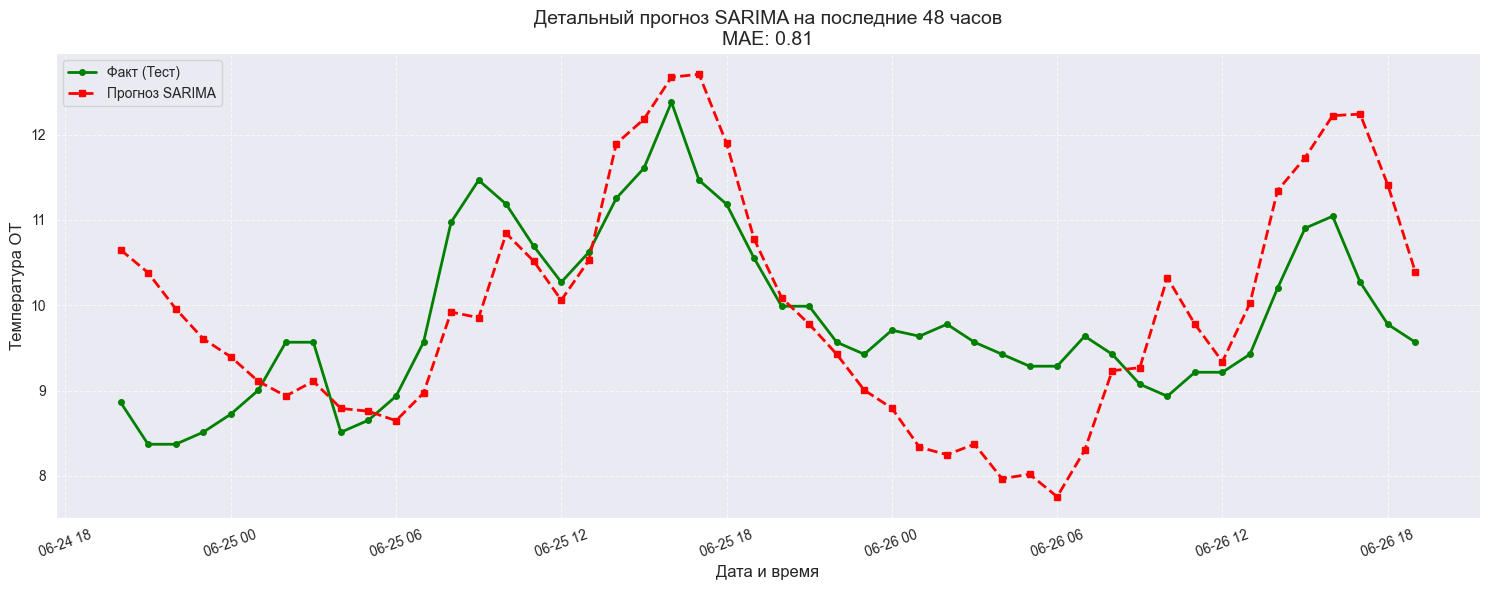

In [17]:


# 1. Получаем прогноз и доверительные интервалы
forecast_object = results_sarima.get_forecast(steps=48)
conf_int = forecast_object.conf_int() # Нижняя и верхняя границы

# 2. Настройка графика
plt.figure(figsize=(15, 6))

# Отрисовка фактических данных за последние 48 часов
plt.plot(test_sarima.index, test_sarima.values,
         label='Факт (Тест)', color='green', marker='o', markersize=4, linewidth=2)

# Отрисовка прогноза
plt.plot(test_sarima.index, y_pred_sarima,
         label='Прогноз SARIMA', color='red', linestyle='--', marker='s', markersize=4, linewidth=2)

plt.title(f'Детальный прогноз SARIMA на последние 48 часов\nMAE: {mae:.2f}', fontsize=14)
plt.xlabel('Дата и время', fontsize=12)
plt.ylabel('Температура OT', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#### LSTM
Нормализация данных и формирование тензоров

In [18]:
# Для LSTM удобнее работать с Dataframe, переводим наши Series обратно
train_df = pd.DataFrame(y_train, columns=['OT'])
test_df = pd.DataFrame(y_test, columns=['OT'])

# Инициализация скалера
scaler = MinMaxScaler(feature_range=(0, 1))

# Обучение и трансформация (используется только целевая колонка)
scaled_train = scaler.fit_transform(train_df)
scaled_test = scaler.transform(test_df)

def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)
# Размер окна (суточный цикл)
WINDOW_SIZE = 24

X_train_lstm, y_train_lstm = create_sequences(scaled_train, WINDOW_SIZE)
X_test_lstm, y_test_lstm = create_sequences(scaled_test, WINDOW_SIZE)

print(f"Форма обучающей выборки для LSTM: {X_train_lstm.shape}")

Форма обучающей выборки для LSTM: (15068, 24, 1)


#### Архитектура нейронной сети и обучение

In [19]:
# Построение архитектуры нейронной сети
model_lstm = Sequential([
    Input(shape=(WINDOW_SIZE, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.3),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

model_lstm.compile(optimizer='adam', loss='mse')

# Использование EarlyStopping для предотвращения переобучения
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Обучение модели
history = model_lstm.fit(
    X_train_lstm, y_train_lstm,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - loss: 0.0064 - val_loss: 7.1894e-04
Epoch 2/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0031 - val_loss: 6.0282e-04
Epoch 3/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - loss: 0.0027 - val_loss: 5.0879e-04
Epoch 4/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.0021 - val_loss: 4.5765e-04
Epoch 5/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0018 - val_loss: 5.6131e-04
Epoch 6/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0017 - val_loss: 3.9361e-04
Epoch 7/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0015 - val_loss: 3.3312e-04
Epoch 8/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0014 - val_loss: 3.6687e-04
Epoch 9/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - loss: 0.0012 - val_loss: 2.9606e-04
Epoch 10/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0011 - val_loss: 2.7782e-04
Epoch 11/20
212/212 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0010 - val_loss: 2.9856e-

#### Визуализация

67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step

--- Результаты LSTM ---
MAE:  0.55
MAPE: 7.04%


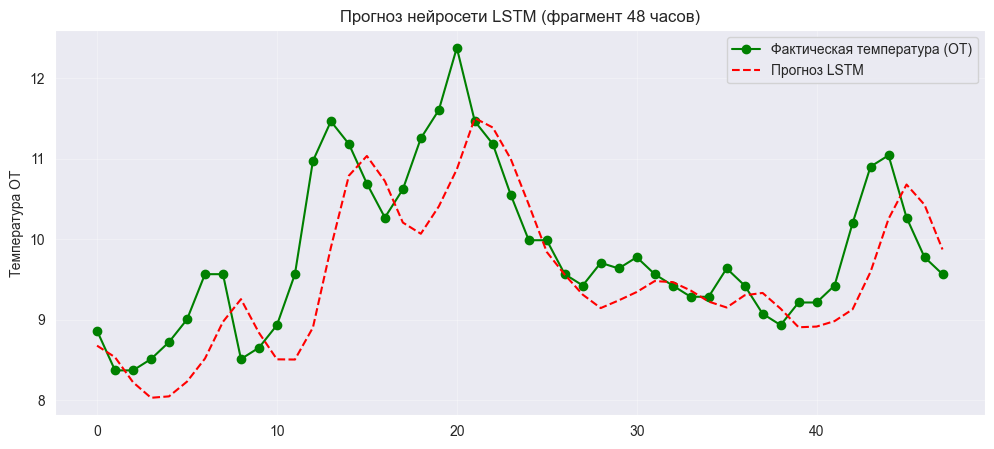

In [20]:
# Генерация прогноза на тестовых данных
lstm_predictions_scaled = model_lstm.predict(X_test_lstm)

# Обратное масштабирование
lstm_predictions = scaler.inverse_transform(lstm_predictions_scaled)
y_test_lstm_real = scaler.inverse_transform(y_test_lstm.reshape(-1, 1))

mask = y_test_lstm_real > 0
mae_lstm = mean_absolute_error(y_test_lstm_real, lstm_predictions)
mape_lstm = np.mean(np.abs((y_test_lstm_real[mask] - lstm_predictions[mask]) / y_test_lstm_real[mask])) * 100

print(f"\n--- Результаты LSTM ---")
print(f"MAE:  {mae_lstm:.2f}")
print(f"MAPE: {mape_lstm:.2f}%")

# Визуализация результатов (фрагмент 48 часов)
plt.figure(figsize=(12, 5))
plt.plot(y_test_lstm_real[-48:], label='Фактическая температура (OT)', marker='o', color='green')
plt.plot(lstm_predictions[-48:], label='Прогноз LSTM', color='red', linestyle='--')
plt.title('Прогноз нейросети LSTM (фрагмент 48 часов)')
plt.ylabel('Температура OT')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()